In [4]:
import os
import pandas as pd

# Find the caption file
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if "caption" in file.lower():
            print(os.path.join(root, file))

/kaggle/input/datasets/adityajn105/flickr8k/captions.txt


In [6]:
caption_file = "/kaggle/input/datasets/adityajn105/flickr8k/captions.txt"

df = pd.read_csv(caption_file)

df.head()

,image,caption
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...


In [27]:
# Select 3 different captions from the Flickr8k dataset
three_captions = df["caption"].sample(3, random_state=123).tolist()

for i, caption in enumerate(three_captions, 1):
    print(f"{i}. {caption}")

1. A young girl in front of a silver car wearing boots , demonstrates some interesting moves .
2. People are drinking and walking in front of a brick building .
3. A man in a striped shirt is demonstrating a product .


In [28]:
!pip install -q diffusers transformers accelerate

In [29]:
import torch
from diffusers import AutoPipelineForText2Image

pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo",
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/1 [00:00<?, ?it/s]

Caption: A young girl in front of a silver car wearing boots , demonstrates some interesting moves .


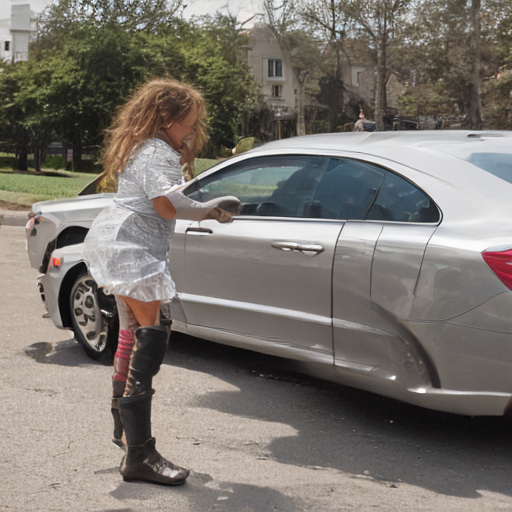

  0%|          | 0/1 [00:00<?, ?it/s]

Caption: People are drinking and walking in front of a brick building .


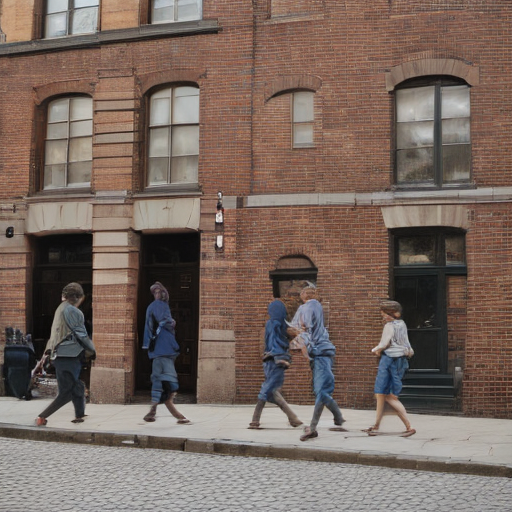

  0%|          | 0/1 [00:00<?, ?it/s]

Caption: A man in a striped shirt is demonstrating a product .


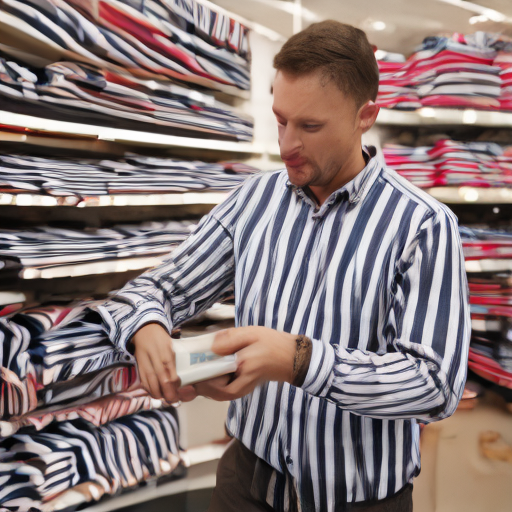

In [32]:
from IPython.display import display

generated_images = []

for caption in three_captions:
    image = pipe(
        caption,
        num_inference_steps=1,
        guidance_scale=0.0
    ).images[0]

    generated_images.append(image)

    print("Caption:", caption)
    display(image)


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

Image 1: A girl is playing in the mud near a car .


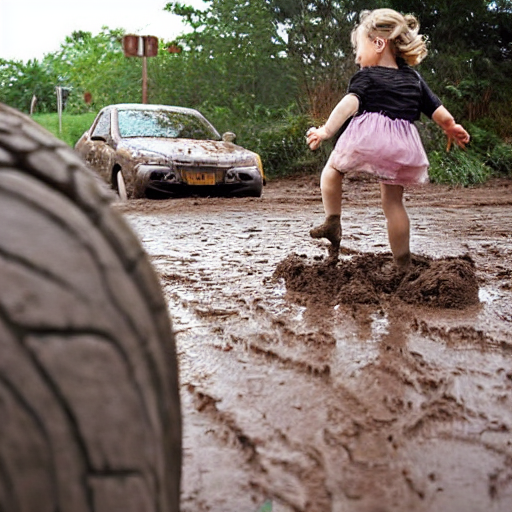

  0%|          | 0/30 [00:00<?, ?it/s]

Image 2: A dog running on grass .


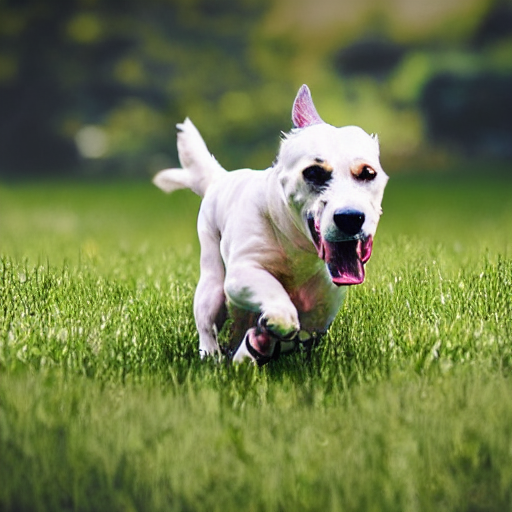

  0%|          | 0/30 [00:00<?, ?it/s]

Image 3: A black dog in water .


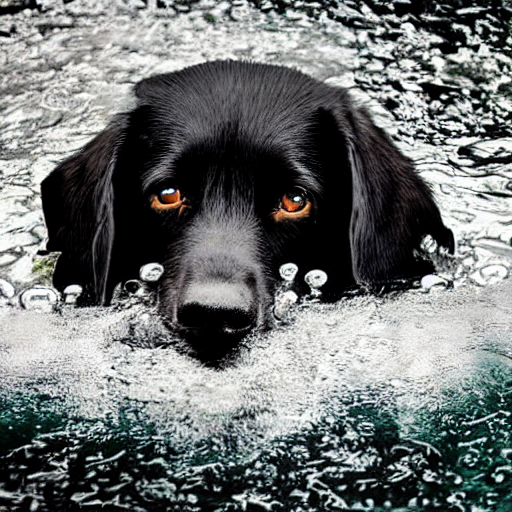

  0%|          | 0/30 [00:00<?, ?it/s]

Image 4: A woman with a blue jacket wears a helmet as she rides a bike .


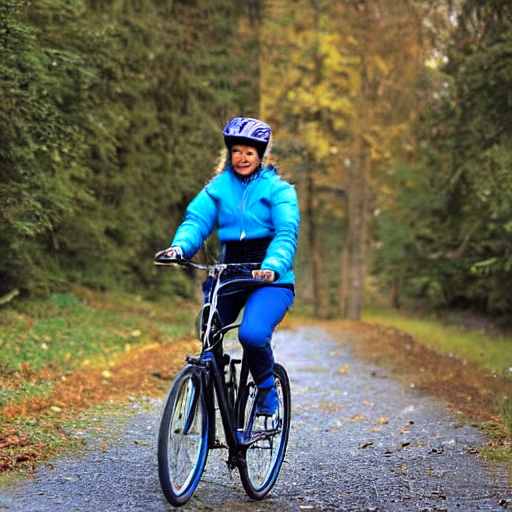

In [33]:
# Install required library
!pip install -q diffusers transformers accelerate

import pandas as pd
import torch
from diffusers import StableDiffusionPipeline

# Load Flickr8k captions
df = pd.read_csv(
    "/kaggle/input/datasets/adityajn105/flickr8k/captions.txt",
    sep=",",
    names=["image", "caption"]
)

# Select 4 different captions from the dataset
captions = df["caption"].sample(4, random_state=123).tolist()

# Load image generation model
pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")

# Generate 4 new images
for i, caption in enumerate(captions, 1):

    prompt = f"Realistic photograph: {caption}"

    image = pipe(
        prompt,
        num_inference_steps=30,
        guidance_scale=7.5
    ).images[0]

    print(f"Image {i}: {caption}")
    display(image)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/40 [00:00<?, ?it/s]


Image 1
Caption: A man in a black fedora smiles at the camera .


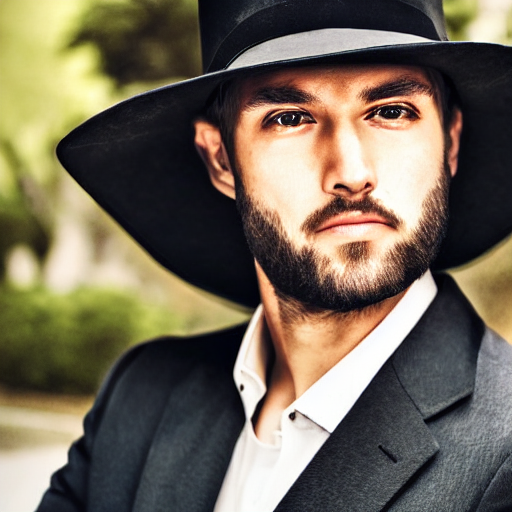

  0%|          | 0/40 [00:00<?, ?it/s]


Image 2
Caption: A blonde boy in a brown jacket sits on a tire swing .


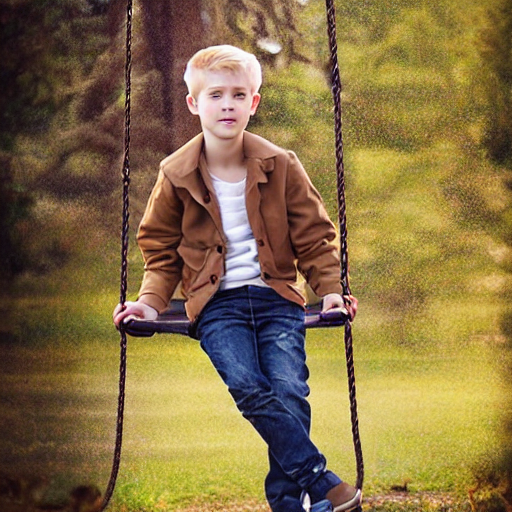

  0%|          | 0/40 [00:00<?, ?it/s]


Image 3
Caption: A child is walking through a puddle wearing green sandals


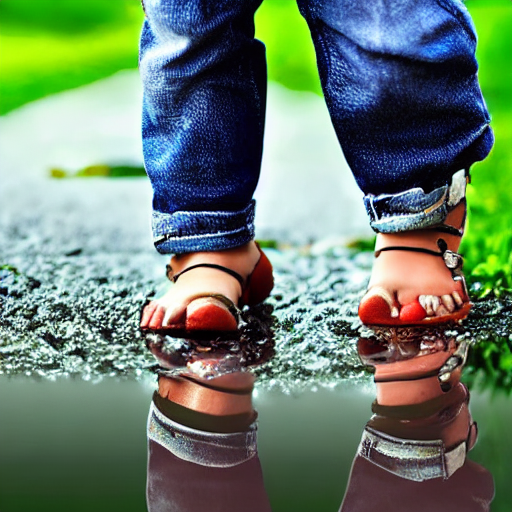

In [34]:
import pandas as pd
import torch
from diffusers import StableDiffusionPipeline
from IPython.display import display

# Load Flickr8k captions
df = pd.read_csv(
    "/kaggle/input/datasets/adityajn105/flickr8k/captions.txt",
    sep=",",
    names=["image", "caption"]
)

# Select 3 new captions from a different part of the dataset
new_captions = df["caption"].iloc[8000:10000].sample(
    3, random_state=456
).tolist()

# Load Stable Diffusion
pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16
).to("cuda")

# Generate 3 new realistic images
for i, caption in enumerate(new_captions, 1):

    prompt = (
        f"Photorealistic high-quality photograph, {caption}, "
        "natural lighting, realistic details, accurate proportions, "
        "sharp focus, realistic colors, DSLR photography"
    )

    image = pipe(
        prompt,
        num_inference_steps=40,
        guidance_scale=8.5
    ).images[0]

    print(f"\nImage {i}")
    print("Caption:", caption)
    display(image)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]


Image 1
Caption: A man jumps off a cliff with a city view below .


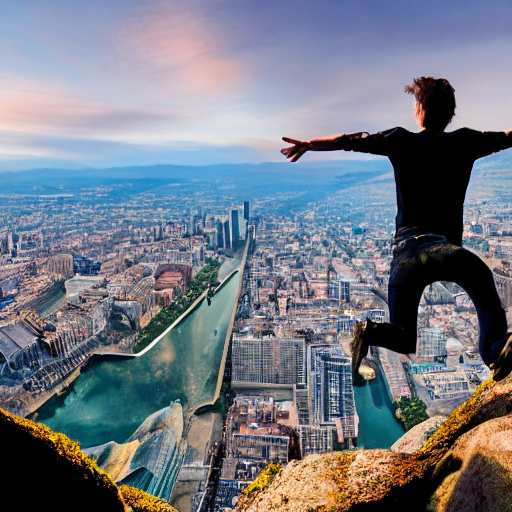

  0%|          | 0/50 [00:00<?, ?it/s]


Image 2
Caption: A man is standing on top of a glacier .


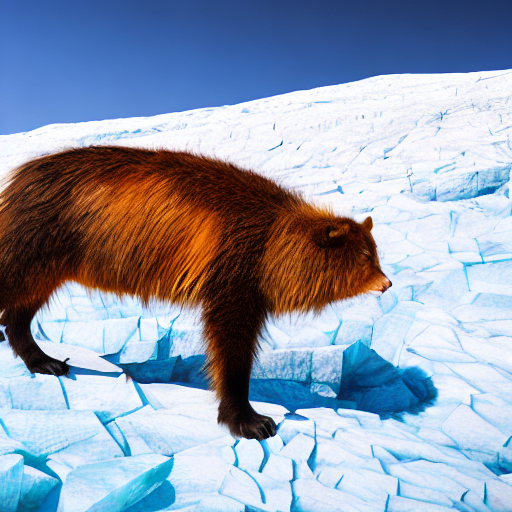

  0%|          | 0/50 [00:00<?, ?it/s]


Image 3
Caption: an older man playing wearing a quilt the bagpipes outside .


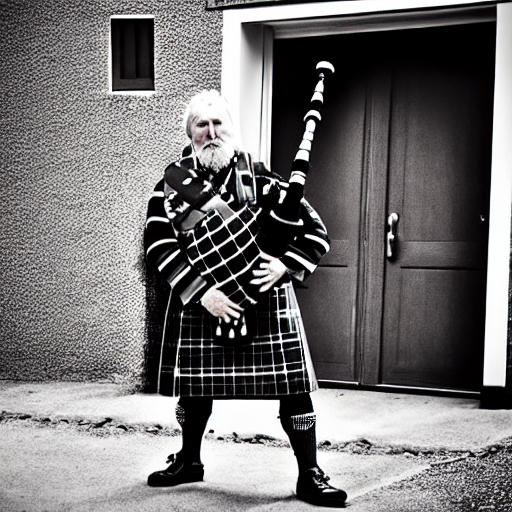

In [36]:
!pip install -q diffusers transformers accelerate

import pandas as pd
import torch
from diffusers import StableDiffusionPipeline
from IPython.display import display

# Load Flickr8k captions
df = pd.read_csv(
    "/kaggle/input/datasets/adityajn105/flickr8k/captions.txt",
    sep=",",
    names=["image", "caption"]
)

# Pick 3 new captions
captions = df["caption"].sample(3, random_state=999).tolist()

# Load Stable Diffusion
pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16
).to("cuda")

# Generate 3 super-realistic images
for i, caption in enumerate(captions, 1):

    prompt = (
        f"Ultra photorealistic professional photograph of {caption}, "
        "realistic human and animal anatomy, natural skin and fur texture, "
        "realistic lighting, natural shadows, detailed environment, "
        "sharp focus, DSLR photography, 35mm lens, high detail, "
        "true-to-life colors, realistic depth of field"
    )

    image = pipe(
        prompt,
        num_inference_steps=50,
        guidance_scale=9
    ).images[0]

    print(f"\nImage {i}")
    print("Caption:", caption)
    display(image)